# PNS limits with the SAFE model

GrOpt models peripheral nerve stimulation (PNS) with the SAFE model (Hebrank and Gebhardt, 2000): three
low-pass filtered versions of the slew rate, weighted per gradient axis. `gropt.get_SAFE` predicts the
stimulation of a waveform, and `add_SAFE` limits it during the solve. Both are given as a fraction of the
stimulation threshold (1.0 = 100%).

The model parameters come from the scanner's `.asc` file (`gropt.readasc.asc_to_safe`), from a datasheet
(`gropt.make_safe_params`), or, as here, from `gropt.get_random_safe_params`, which draws a realistic but
made-up set.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import gropt

pns, cns = gropt.get_random_safe_params(42)   # (PNS, cardiac) models, one value per axis (x, y, z)
pns

{'a1': array([0.28, 0.24, 0.29]),
 'a2': array([0.54, 0.42, 0.6 ]),
 'a3': array([0.18, 0.34, 0.11]),
 'g_scale': array([0.34, 0.34, 0.29]),
 'stim_limit': array([29. , 27.4, 38.5]),
 'tau1': array([0.00086, 0.00093, 0.00078]),
 'tau2': array([0.011, 0.013, 0.01 ]),
 'tau3': array([0.00027, 0.00023, 0.00025])}

In [2]:
def flow_encode(N, pns_lim=None):
    gp = gropt.GroptParams()
    gp.dt = 10e-6
    gp.N = N
    gp.vec_init_simple()
    gp.add_gmax(0.08)
    gp.add_smax(200)
    gp.add_moment(0, 0.0, project=True)
    gp.add_moment(1, 14.0, project=True)
    if pns_lim is not None:
        gp.add_SAFE(pns_lim, safe_params=pns)
    return gp


def shortest(make, lo, hi):
    """Smallest N in (lo, hi] whose solve converges (see the flow-encoding example)."""
    best = gropt.solve(make(hi))
    if not best.converged:
        raise ValueError(f'N = {hi} is not feasible; raise hi')
    while hi - lo > 1:
        mid = (lo + hi) // 2
        r = gropt.solve(make(mid))
        if r.converged:
            hi, best = mid, r
        else:
            lo = mid
    return hi, best

## Predict, then limit

The shortest flow encode without a PNS limit, and its predicted stimulation on the x axis:

In [3]:
N0, r0 = shortest(flow_encode, 50, 300)
stim0 = gropt.get_SAFE(r0.X, 10e-6, safe_params=pns)
print(f'No PNS limit: N = {N0}, peak stimulation {np.abs(stim0).max():.2f}')

No PNS limit: N = 133, peak stimulation 0.68


Now the shortest one that stays under 50% of the threshold:

PNS <= 0.5:   N = 136, peak stimulation 0.50

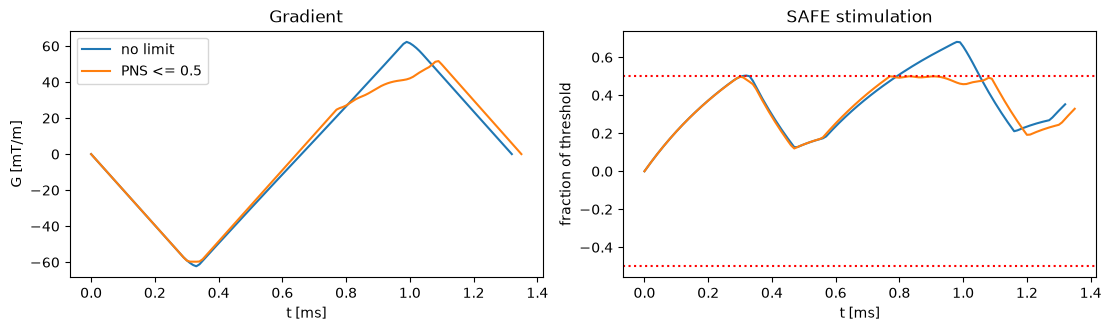

In [4]:
N1, r1 = shortest(lambda N: flow_encode(N, pns_lim=0.5), 50, 300)
stim1 = gropt.get_SAFE(r1.X, 10e-6, safe_params=pns)
print(f'PNS <= 0.5:   N = {N1}, peak stimulation {np.abs(stim1).max():.2f}')

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), layout='constrained')
for N, r, stim, label in ((N0, r0, stim0, 'no limit'), (N1, r1, stim1, 'PNS <= 0.5')):
    t_ms = np.arange(N) * 10e-3
    axs[0].plot(t_ms, r.X * 1e3, label=label)
    axs[1].plot(t_ms, stim, label=label)
axs[1].axhline(0.5, ls=':', color='r')
axs[1].axhline(-0.5, ls=':', color='r')
axs[0].set(xlabel='t [ms]', ylabel='G [mT/m]', title='Gradient')
axs[1].set(xlabel='t [ms]', ylabel='fraction of threshold', title='SAFE stimulation')
axs[0].legend()
plt.show()

The PNS-limited waveform slews more gently, at the cost of a slightly longer duration.

## Notes

- **Axes.** `new_first_axis` picks which axis's coefficients apply to the first gradient axis. With
  several gradient axes, `add_SAFE` limits the root-sum-square of the per-axis stimulation, as the scanner
  does. The model is not rotation invariant, so check every orientation the waveform will be played in.
- **Raster.** Set `gparams.safe_alpha_exact = True` before `add_SAFE` on coarse rasters: the default filter
  discretization under-reports stimulation at large `dt` (about 8% at 400 µs), the exact one does not depend
  on `dt`. At 10 µs both agree.
- **Time-varying limits.** `add_SAFE_vec` takes one limit per sample.
- **Diffusion.** `DiffParams(pns_lim=..., cns_lim=...)` adds PNS and cardiac stimulation limits with
  the same model; see [Diffusion encoding](../diffusion/diffusion.ipynb).